# Bài 4: Phân tích ACF & PACF – Đề xuất (p, d, q)

**Dataset:** AirPassengers · **Thư viện:** `statsmodels` (ACF/PACF), `matplotlib`, `pandas`

**Quy tắc áp dụng:** chỉ dùng tập **Train** (không đụng vào Test) và chỉ vẽ ACF/PACF trên chuỗi **đã lấy sai phân**, không vẽ trên chuỗi gốc.
Các hàm `plot_acf_pacf` và `significant_lags` nằm trong `src/lab02_utils/stats.py`.
Ngưỡng tin cậy 95% dùng để đọc "cắt cụt" trong các bảng là ±1.96/√n; dải xanh trên đồ thị ACF là dải Bartlett nên rộng dần theo lag, còn dải của PACF là ±1.96/√n.

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.stats import plot_acf_pacf, significant_lags

plt.style.use('seaborn-v0_8-whitegrid')

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

## Bước 1: Nạp tập Train và lấy sai phân

In [2]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists():
    # Dùng đúng tập Train đã xuất ở Bài 1
    train = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')['Passengers']
else:
    # Chưa chạy Bài 1: chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    train = train_df['Passengers']

diff_1 = train.diff()              # d = 1: loại xu hướng (cho ARIMA)
diff_1_12 = train.diff().diff(12)  # d = 1 và D = 1 (s = 12): loại cả mùa vụ (quan sát cho SARIMA)

print(f"Train: {len(train)} quan sát | Sai phân d=1: {diff_1.notna().sum()} | Sai phân d=1, D=1: {diff_1_12.notna().sum()}")

Train: 115 quan sát | Sai phân d=1: 114 | Sai phân d=1, D=1: 102


## Bước 2: ACF & PACF của chuỗi sai phân bậc 1 (d = 1) – đề xuất (p, q) cho ARIMA
Đường đỏ chấm là các lag mùa vụ (12, 24, 36). Với ARIMA, mình đọc **các lag ngắn** (1, 2, 3, ...) để chọn p và q.

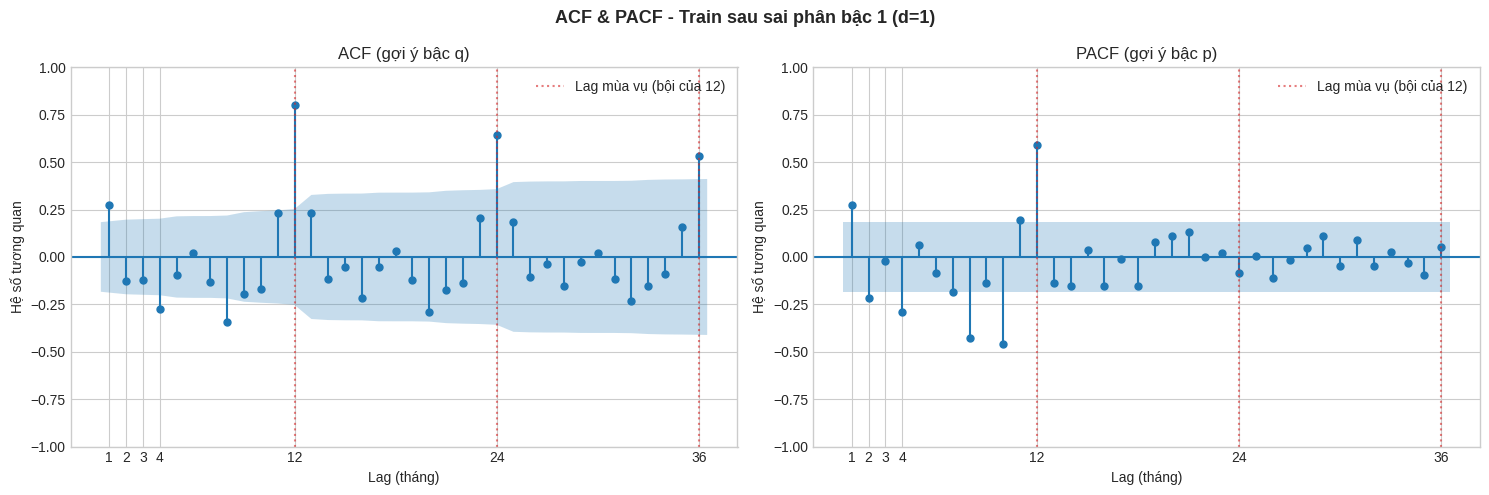

n = 114, ngưỡng tin cậy 95% = ±0.184


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,0.27,0.27,Có,Có
2,-0.13,-0.22,-,Có
3,-0.12,-0.02,-,-
4,-0.28,-0.29,Có,Có
5,-0.10,0.06,-,-
6,0.02,-0.09,-,-
12,0.80,0.59,Có,Có
24,0.64,-0.09,Có,-
36,0.53,0.05,Có,-


Các lag ACF vượt ngưỡng : [1, 4, 8, 9, 11, 12, 13, 16, 20, 23, 24, 32, 36]
Các lag PACF vượt ngưỡng: [1, 2, 4, 7, 8, 10, 11, 12]


In [3]:
plot_acf_pacf(diff_1, lags=36, title='ACF & PACF - Train sau sai phân bậc 1 (d=1)',
              save_path=str(fig_dir / 'bai4_acf_pacf_d1.png'))

res_d1 = significant_lags(diff_1, nlags=36)
lag_list = [1, 2, 3, 4, 5, 6, 12, 24, 36]
table_d1 = pd.DataFrame({
    'ACF': [res_d1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1['n']}, ngưỡng tin cậy 95% = ±{res_d1['bound']:.3f}")
display(table_d1)
print('Các lag ACF vượt ngưỡng :', res_d1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1['pacf_sig'])

**Nhận xét (chuỗi d = 1, ngưỡng ±0.184):**
- **ACF:** lag 1 = 0.27 vượt ngưỡng, còn lag 2 (−0.13) và lag 3 (−0.12) nằm trong ngưỡng, nên ACF **cắt cụt sau lag 1**. Lag 4 (−0.28) vượt ngưỡng, và các lag 12, 24, 36 lần lượt là 0.80, 0.64, 0.53, giảm rất chậm. Đó là dấu vết mùa vụ chu kỳ 12 chứ không phải cấu trúc MA ngắn hạn.
- **PACF:** lag 1 = 0.27 và lag 2 = −0.22 đều vượt ngưỡng, lag 3 (−0.02) nằm trong ngưỡng, nên PACF **cắt cụt sau lag 2**. Lag 2 chỉ vượt ngưỡng một chút. Các lag 4, 7, 8, 10, 11, 12 cũng vượt ngưỡng, lại là ảnh hưởng của mùa vụ (lag 12 = 0.59).

## Bước 3: ACF & PACF của chuỗi sai phân bậc 1 + mùa vụ (d = 1, D = 1, s = 12)
Phần này chỉ để **quan sát các lag mùa vụ** (bội của 12) phục vụ Bài 6 (SARIMA), chưa chốt tham số.

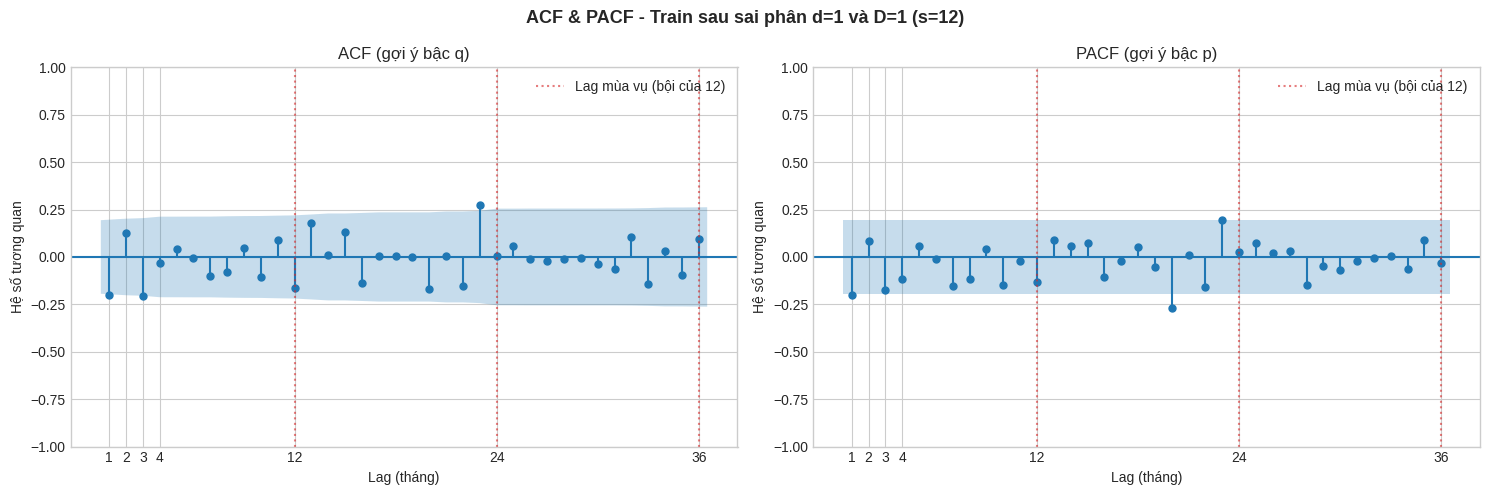

n = 102, ngưỡng tin cậy 95% = ±0.194


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,-0.20,-0.20,Có,Có
2,0.12,0.09,-,-
3,-0.21,-0.17,Có,-
4,-0.03,-0.12,-,-
5,0.04,0.06,-,-
6,-0.01,-0.01,-,-
12,-0.17,-0.13,-,-
24,0.00,0.02,-,-
36,0.10,-0.03,-,-


Các lag ACF vượt ngưỡng : [1, 3, 23]
Các lag PACF vượt ngưỡng: [1, 20, 23]


In [4]:
plot_acf_pacf(diff_1_12, lags=36, title='ACF & PACF - Train sau sai phân d=1 và D=1 (s=12)',
              save_path=str(fig_dir / 'bai4_acf_pacf_d1_D1.png'))

res_d1D1 = significant_lags(diff_1_12, nlags=36)
table_d1D1 = pd.DataFrame({
    'ACF': [res_d1D1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1D1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1D1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1D1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1D1['n']}, ngưỡng tin cậy 95% = ±{res_d1D1['bound']:.3f}")
display(table_d1D1)
print('Các lag ACF vượt ngưỡng :', res_d1D1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1D1['pacf_sig'])

**Nhận xét (chuỗi d = 1, D = 1, ngưỡng ±0.194):**
- Sau khi thêm sai phân mùa vụ, các đỉnh lớn ở lag 12, 24, 36 **biến mất**: lag 12 chỉ còn −0.17 (ACF) và −0.13 (PACF), lag 24 gần bằng 0. Chuỗi trông gần giống nhiễu trắng.
- Chỉ còn vài lag vượt ngưỡng: ACF ở lag 1 (−0.20) và lag 3 (−0.21), cả hai sát ngưỡng; PACF ở lag 1 (−0.20). Các lag 20 và 23 vượt ngưỡng nhưng không phải bội của 12, và khi xét 36 lag thì khoảng 5% (cỡ 2 lag) vượt ngưỡng chỉ do ngẫu nhiên, nên mình xem chúng là nhiễu.
- Vì lag 12 và 24 đều nằm trong ngưỡng, **chưa có bằng chứng mạnh cho P và Q** (hướng quan sát: P, Q thuộc {0, 1}, chốt bằng AIC/BIC và chẩn đoán phần dư ở Bài 6).

## Trả lời các câu hỏi của Bài 4

**1. ACF cắt cụt ở lag nào?**
Ở **lag 1** (chuỗi d = 1): lag 1 = 0.27 vượt ngưỡng ±0.184, lag 2 và lag 3 nằm trong ngưỡng. Các lag 4, 12, 24, 36 vượt ngưỡng nhưng do mùa vụ nên không dùng để chọn q.

**2. PACF cắt cụt ở lag nào?**
Ở **lag 2**: lag 1 (0.27) và lag 2 (−0.22) vượt ngưỡng, lag 3 (−0.02) nằm trong ngưỡng. Lag 2 chỉ vượt sát ngưỡng nên p = 1 cũng là lựa chọn hợp lý.

**3. Gợi ý mô hình ARIMA(p, d, q)?**
- **d = 1** (sai phân bậc 1 để loại xu hướng, đã làm ở Bài 3).
- **p** đọc từ PACF: 2 (hoặc 1 nếu coi lag 2 là sát ngưỡng). **q** đọc từ ACF: 1.
- Đề xuất thử **ARIMA(2,1,1)** và **ARIMA(1,1,1)**. Đây chính là hai mô hình dùng ở Bài 5, quyết định cuối cùng dựa vào AIC/BIC và chẩn đoán phần dư.

**4. Lưu ý khi đọc kết quả**
- Ở Bài 3, ADF trên chuỗi Train sau sai phân bậc 1 có p-value = 0.106, tức chưa đạt chuẩn dừng ở mức 5%. Điều này khớp với việc ACF ở các lag 12, 24, 36 giảm rất chậm: còn mùa vụ chưa được loại bỏ.
- Vì mùa vụ làm nhiễu cả ACF lẫn PACF ở nhiều lag (4, 8, 12, ...), việc đọc "cắt cụt" ở lag ngắn chỉ mang tính gợi ý. Phần mùa vụ nên xử lý bằng SARIMA với D = 1, s = 12 ở Bài 6.
- Các tham số (P, D, Q) vẫn do người làm quyết định ở Bài 6; ở trên mới là quan sát: sau d = 1, D = 1 các lag mùa vụ 12 và 24 đều nằm trong ngưỡng.